# Shape distances, elastic and varifold ideas

How do alignment choices and deformation costs change the meaning of similarity in a small shape cohort?

Fall 2024.


## Predict the cohort
A is a reference, B a posed copy, C a larger copy, D a local bulge and E a changed cyclic start. Predict which pairs should agree under proper rigid and cyclic comparison. These are synthetic contours, not patient groups.

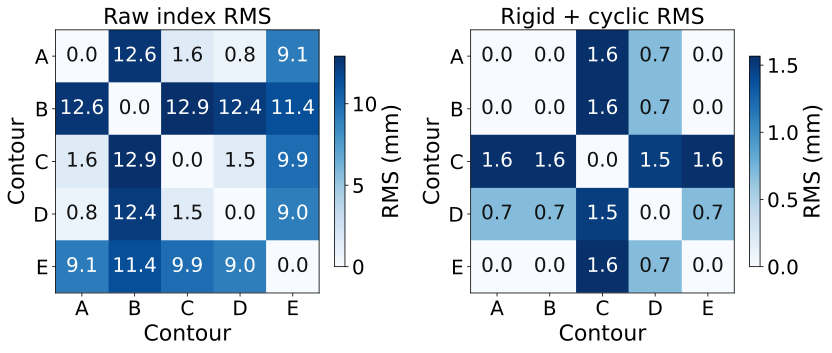

[[0.0,
  4.632437998758358e-15,
  1.566670095042511,
  0.6836546720684521,
  3.839187438840846e-15],
 [4.632437998758358e-15,
  0.0,
  1.5666700950425116,
  0.6836546720684499,
  3.1541070254086604e-15],
 [1.566670095042511,
  1.5666700950425116,
  0.0,
  1.4868909716084544,
  1.5666700950425096],
 [0.6836546720684521,
  0.6836546720684499,
  1.4868909716084544,
  0.0,
  0.6836546720684522],
 [3.839187438840846e-15,
  3.1541070254086604e-15,
  1.5666700950425096,
  0.6836546720684522,
  0.0]]

In [1]:
import numpy as np
from demo import cohort, pairwise, aligned_distance, displacement_fields, displacement_cost, run
from IPython.display import SVG, display
report=run()
display(SVG(filename="cohort-distances.svg"))
report["rigid_cyclic_RMS_mm"]

## Check the comparison contract
Explain why allowing the identity transform bounds the minimum by the raw RMS. Check symmetry and known copies. Read numbers, not matching shades, across the two differently scaled panels.

In [2]:
shapes=cohort()
names,raw=pairwise(shapes)
_,aligned=pairwise(shapes,aligned=True)
assert np.allclose(aligned,aligned.T)
assert np.all(aligned<=raw+1e-12)
assert aligned[0,1]<1e-12 and aligned[0,4]<1e-12
assert aligned[0,2]>.1
print("Known copies and retained size difference passed.")

Known copies and retained size difference passed.


## Predict, then modify the weight
Two fields have equal RMS amplitude but different neighbor variation. Predict the zero-weight tie. Choose another nonnegative weight, keeping the grid fixed, and explain the change in scores.

0.0 [1.0, 1.0000000000000002]
0.5 [1.0239374687977971, 1.4471049895051786]
2.0 [1.0957498751911885, 2.788419958020714]


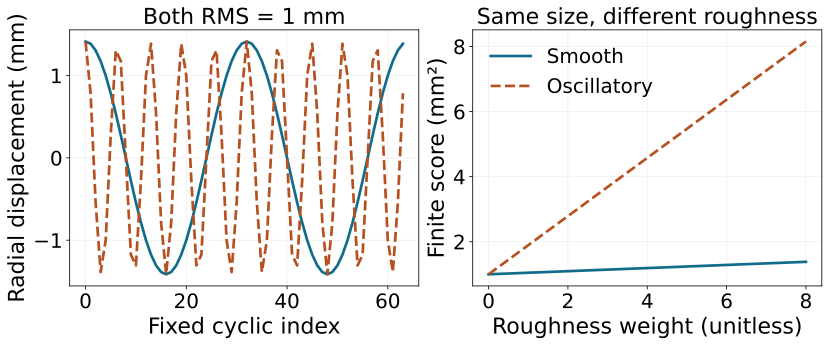

In [3]:
theta,fields=displacement_fields()
for weight in [0.,.5,2.]:
    print(weight,[displacement_cost(u,weight)["score_mm2"] for u in fields])
display(SVG(filename="displacement-cost.svg"))

## Test a limit and state the scope
Use a zero field as a limit. Then compare one field with a doubled copy. Explain why a correct quadratic-scaling check still establishes no elastic path or clinical validation.

In [4]:
u=fields[0]
assert displacement_cost(np.zeros_like(u),2.)["score_mm2"]==0
a=displacement_cost(u,2.)["score_mm2"]
b=displacement_cost(2*u,2.)["score_mm2"]
assert np.isclose(b,4*a)
print("Quadratic scaling:",a,b)

Quadratic scaling: 1.0957498751911885 4.382999500764754
